In [1]:
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_curve, auc

In [2]:
xgb_model = pickle.load(open('../results/xgboost_tuned_model.pkl', 'rb'))
X_test = pd.read_csv('../data/X_test.csv')
y_test = pd.read_csv('../data/y_test.csv').squeeze()

In [3]:
y_pred       = xgb_model.predict(X_test)
y_pred_proba = xgb_model.predict_proba(X_test)[:, 1]

c:\Users\Maneshna\miniconda3\envs\torch_env\lib\site-packages\xgboost\core.py:158: UserWarning: [19:39:07] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\common\error_msg.cc:58: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  warnings.warn(smsg, UserWarning)


In [5]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f"True Negatives  (correctly caught benign): {tn}")
print(f"False Positives (benign flagged as attack): {fp}")
print(f"False Negatives (attacks missed):           {fn}")
print(f"True Positives  (attacks caught):           {tp}")
print(f"\nFalse Positive Rate: {fp / (fp + tn):.2%}")
print(f"False Negative Rate: {fn / (fn + tp):.2%}")

True Negatives  (correctly caught benign): 87924
False Positives (benign flagged as attack): 13
False Negatives (attacks missed):           2
True Positives  (attacks caught):           50343

False Positive Rate: 0.01%
False Negative Rate: 0.00%


In [6]:
analyst_time_per_alert = 5     # minutes per alert
flows_per_day          = 100_000
hourly_cost            = 50    # USD per analyst hour


In [7]:
fpr = fp / (fp + tn)
daily_fps  = fpr * flows_per_day
daily_cost = (daily_fps * analyst_time_per_alert / 60) * hourly_cost

print(f"Estimated daily false positives: {daily_fps:.0f}")
print(f"Analyst hours wasted per day:    {daily_fps * analyst_time_per_alert / 60:.1f} hrs")
print(f"Estimated daily cost:            ${daily_cost:.2f}")

Estimated daily false positives: 15
Analyst hours wasted per day:    1.2 hrs
Estimated daily cost:            $61.60


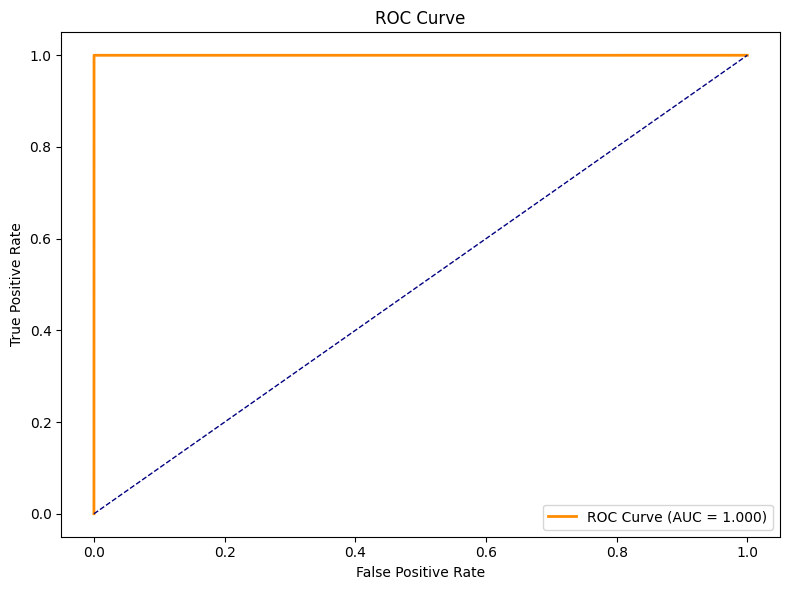

AUC: 1.0000


In [8]:
fpr_arr, tpr_arr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr_arr, tpr_arr)

plt.figure(figsize=(8, 6))
plt.plot(fpr_arr, tpr_arr, color='darkorange', lw=2,
         label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../results/roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"AUC: {roc_auc:.4f}")

In [9]:
summary = {
    'True Negatives':  tn,
    'False Positives': fp,
    'False Negatives': fn,
    'True Positives':  tp,
    'False Positive Rate': round(fp / (fp + tn), 4),
    'False Negative Rate': round(fn / (fn + tp), 4),
    'AUC': round(roc_auc, 4),
    'Daily FP Cost (USD)': round(daily_cost, 2),
}

pd.DataFrame([summary]).to_csv('../results/false_positive_analysis.csv', index=False)
print("Summary saved to ../results/false_positive_analysis.csv")

Summary saved to ../results/false_positive_analysis.csv
